In [145]:
### This Script is designed to parse and aggregate Replica data so that it can be placed into Flowmap_Blue


In [144]:
TO DO
- 1 DONE Import Replica Data and Census Data
- 2 DONE Make Centroids for census tracts identified above.
    - These should have all census tract attributes
    - Create Longitude / Latitude Fields for the centroids
- 3 DONE Join Replica Data to Centroids
- 4 Create sheet of origin and destination locations that matches Flowmap blue template
- 5 Review sample Flowmap Blue project to see which parts of template are necessary
- 6 Strategize how Flows can be aggregated. Eventually this should be interactive and flexible,
    so that users can choose the times, dates, weeks etc that they are interested in mapping. 
        - Part of this might also tie into the flowmap template, which allows users to create 
          aggregation / division fields. 
- 7 Make drag and drop flask app, that handles replica csvs.
    - Drop replica file into browser window
    -select days and times
    -python identifies county(ies) and parses file based on time selections
    -creates flowmap compatible sheet. 
-8 Quantify the number of trips happening within the same census tract. How shou
        

Questions
---------
-How are census tracts named in Replica Data vs in the Census Geographies?
    -Replica Data appears to use Census GEOID column
    
-Some destination tracts are populated with the value "aggregated_low_volumes"
    -What exactly does this mean and how should it be handled
    -Rows with this value appear to have proper GEOIDs in Origin column. 


SyntaxError: invalid syntax (<ipython-input-144-aad230150d1f>, line 1)

In [146]:
import os
import pandas as pd
import xlsxwriter
import geopandas as gpd
import matplotlib.pyplot as plt

In [147]:
#Replica Data
replica_data = "/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/Alameda-County--CA-&-4-other-areas_O-D-data_Trips-ending-in-location_Tract_weekof_Jan-27--2020.csv"

#Flowmap Template
flowmap_blue = "/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/Flowmap.blue template spreadsheet.xlsx"

#California Census Tracts -  Cartographic Boundaries
census_tracts = "/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/cb_2018_06_tract_500k/cb_2018_06_tract_500k.shp"

excel_output= '/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/Script_excel_output/flowmap_blue_script_output.xlsx'


print("replica filepath is valid: ",  os.path.isfile(replica_data))
print("flowmap template filepath is valid: ", os.path.isfile(flowmap_blue))
print("census tract filepath is valid: ",  os.path.isfile(census_tracts))

replica filepath is valid:  True
flowmap template filepath is valid:  True
census tract filepath is valid:  True


In [148]:
os.path.isfile(replica_data)

True

In [149]:
# Create dataframe from Replica data
replica = pd.read_csv(replica_data)


flowmap_1 = pd.read_excel(flowmap_blue,0)
flowmap_locations = pd.read_excel(flowmap_blue,1)
flowmap_flows = pd.read_excel(flowmap_blue,2)


In [150]:
# Create geodataframe from Replica data

census_tracts = gpd.read_file(census_tracts)


In [153]:
census_tracts = census_tracts.to_crs("EPSG:2227")

In [154]:
census_tracts.crs

<Projected CRS: EPSG:2227>
Name: NAD83 / California zone 3 (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: USA - California - SPCS - 3
- bounds: (-123.02, 36.73, -117.83, 38.71)
Coordinate Operation:
- name: SPCS83 California zone 3 (US Survey feet)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [155]:
alameda = census_tracts.loc[census_tracts['COUNTYFP'] == '001']


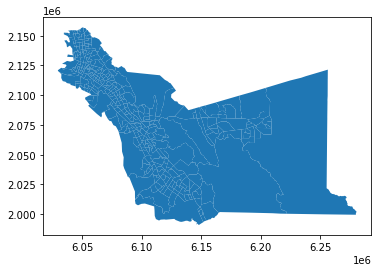

In [156]:
alameda.plot()

In [157]:
alameda.crs

<Projected CRS: EPSG:2227>
Name: NAD83 / California zone 3 (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: USA - California - SPCS - 3
- bounds: (-123.02, 36.73, -117.83, 38.71)
Coordinate Operation:
- name: SPCS83 California zone 3 (US Survey feet)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [158]:
#Dissolve census tracts by county
ct_dis = census_tracts.dissolve(by='COUNTYFP')

In [159]:
ct_dis.columns

Index(['geometry', 'STATEFP', 'TRACTCE', 'AFFGEOID', 'GEOID', 'NAME', 'LSAD',
       'ALAND', 'AWATER'],
      dtype='object')

In [160]:
#df['index1'] = df.index
ct_dis['COUNTYFP'] = ct_dis.index

In [161]:
alam = ct_dis.loc[ct_dis['COUNTYFP'] == '001']

In [162]:
alam.crs

<Projected CRS: EPSG:2227>
Name: NAD83 / California zone 3 (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: USA - California - SPCS - 3
- bounds: (-123.02, 36.73, -117.83, 38.71)
Coordinate Operation:
- name: SPCS83 California zone 3 (US Survey feet)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

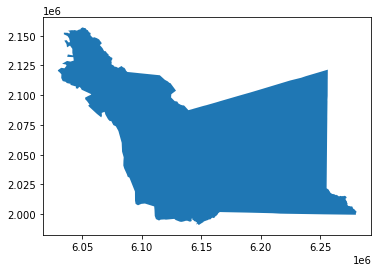

In [163]:
alam.plot()

In [164]:
# Buffer Alameda County
alam_b = alam.buffer(900000, 30000)
print(type(alam_b))

# Buffer function ouputs geoseries, but we want a geodataframe
# Convert buffer output to geodataframe
alam_b = gpd.GeoDataFrame(gpd.GeoSeries(alam_b))

# Set geometry column
alam_b = alam_b.rename(columns={0:'geometry'}).set_geometry('geometry')

# Set CRS
print(alam_b.crs)
alam_b.crs = 'epsg:2227'
alam_b.crs

<class 'geopandas.geoseries.GeoSeries'>
None


<Projected CRS: EPSG:2227>
Name: NAD83 / California zone 3 (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: USA - California - SPCS - 3
- bounds: (-123.02, 36.73, -117.83, 38.71)
Coordinate Operation:
- name: SPCS83 California zone 3 (US Survey feet)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

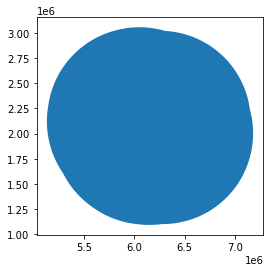

In [165]:
alam_b.plot()

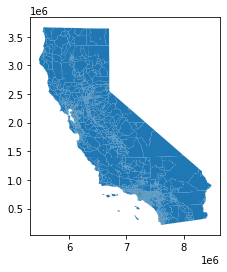

In [166]:
census_tracts.plot()

In [167]:
#Intersect overlay function clips geometry. This will not work because these are census tract.
#What we want is a filtered selection of any census tract that intersects with the buffered county
#geopandas.sjoin(left_df, right_df, how='inner', op='intersects', lsuffix='left', rsuffix='right')
ctracts = gpd.sjoin(census_tracts, alam_b, how='inner', op='intersects')

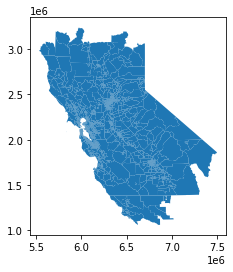

In [168]:
ctracts.plot()

In [169]:
ctracts

,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,index_right
0,06,009,000300,1400000US06009000300,06009000300,3,CT,457009794,394122,"POLYGON ((6485818.537 2264581.233, 6486403.477...",001
1,06,011,000300,1400000US06011000300,06011000300,3,CT,952744514,195376,"POLYGON ((5994135.989 2601413.979, 5994109.508...",001
2,06,013,303102,1400000US06013303102,06013303102,3031.02,CT,6507019,0,"POLYGON ((6207290.652 2177566.454, 6211693.653...",001
3,06,013,303202,1400000US06013303202,06013303202,3032.02,CT,3725528,0,"POLYGON ((6208958.586 2174910.940, 6210865.918...",001
4,06,013,303203,1400000US06013303203,06013303203,3032.03,CT,6354210,0,"POLYGON ((6202766.084 2173246.066, 6202958.261...",001
...,...,...,...,...,...,...,...,...,...,...,...
8026,06,075,025100,1400000US06075025100,06075025100,251,CT,556958,0,"POLYGON ((6009240.633 2098434.803, 6009615.528...",001
8027,06,085,503108,1400000US06085503108,06085503108,5031.08,CT,2315171,0,"POLYGON ((6159278.794 1929463.665, 6159669.443...",001
8036,06,075,022902,1400000US06075022902,06075022902,229.02,CT,161833,0,"POLYGON ((6008928.069 2102740.880, 6009736.900...",001
8038,06,099,003300,1400000US06099003300,06099003300,33,CT,640784444,2596432,"POLYGON ((6275323.585 1997170.009, 6276299.131...",001


In [170]:
# Create Centroids for study area census tracts

ctracts['geometry'] = ctracts.centroid




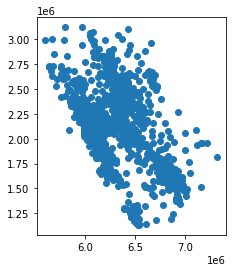

In [171]:
ctracts.plot()

In [172]:
ctracts


,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,index_right
0,06,009,000300,1400000US06009000300,06009000300,3,CT,457009794,394122,POINT (6536326.292 2273328.864),001
1,06,011,000300,1400000US06011000300,06011000300,3,CT,952744514,195376,POINT (6055555.019 2594457.456),001
2,06,013,303102,1400000US06013303102,06013303102,3031.02,CT,6507019,0,POINT (6213540.858 2173479.749),001
3,06,013,303202,1400000US06013303202,06013303202,3032.02,CT,3725528,0,POINT (6211361.551 2167870.008),001
4,06,013,303203,1400000US06013303203,06013303203,3032.03,CT,6354210,0,POINT (6206355.625 2169655.745),001
...,...,...,...,...,...,...,...,...,...,...,...
8026,06,075,025100,1400000US06075025100,06075025100,251,CT,556958,0,POINT (6010129.935 2098981.530),001
8027,06,085,503108,1400000US06085503108,06085503108,5031.08,CT,2315171,0,POINT (6162035.435 1928632.937),001
8036,06,075,022902,1400000US06075022902,06075022902,229.02,CT,161833,0,POINT (6009389.846 2101682.141),001
8038,06,099,003300,1400000US06099003300,06099003300,33,CT,640784444,2596432,POINT (6337899.429 2005608.905),001


In [173]:
print(type(ctracts))

<class 'geopandas.geodataframe.GeoDataFrame'>


In [174]:
ctracts = ctracts.to_crs("EPSG:4326")

In [175]:
ctracts.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [176]:
# Make Lat/Lon columns
# df['lon'] = df.point_object.x
# df['lat'] = df.point_object.y

ctracts['lon'] = ctracts.geometry.x
ctracts['lat'] = ctracts.geometry.y

In [177]:
# CREATE POINTS FROM LAT LON

# gdf = geopandas.GeoDataFrame(
#     df, geometry=geopandas.points_from_xy(df.Longitude, df.Latitude))
points = ctracts[['lon', 'lat']]

points_gdf = gpd.GeoDataFrame(
                points, geometry=gpd.points_from_xy(points.lon, points.lat))

In [178]:
print(type(points_gdf))

<class 'geopandas.geodataframe.GeoDataFrame'>


In [179]:
ctracts

,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,index_right,lon,lat
0,06,009,000300,1400000US06009000300,06009000300,3,CT,457009794,394122,POINT (-120.58823 38.23818),001,-120.588226,38.238179
1,06,011,000300,1400000US06011000300,06011000300,3,CT,952744514,195376,POINT (-122.28320 39.10664),001,-122.283202,39.106639
2,06,013,303102,1400000US06013303102,06013303102,3031.02,CT,6507019,0,POINT (-121.70750 37.95784),001,-121.707504,37.957840
3,06,013,303202,1400000US06013303202,06013303202,3032.02,CT,3725528,0,POINT (-121.71481 37.94236),001,-121.714810,37.942358
4,06,013,303203,1400000US06013303203,06013303203,3032.03,CT,6354210,0,POINT (-121.73225 37.94708),001,-121.732249,37.947082
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8026,06,075,025100,1400000US06075025100,06075025100,251,CT,556958,0,POINT (-122.40763 37.74398),001,-122.407627,37.743976
8027,06,085,503108,1400000US06085503108,06085503108,5031.08,CT,2315171,0,POINT (-121.87367 37.28351),001,-121.873668,37.283508
8036,06,075,022902,1400000US06075022902,06075022902,229.02,CT,161833,0,POINT (-122.41038 37.75135),001,-122.410376,37.751350
8038,06,099,003300,1400000US06099003300,06099003300,33,CT,640784444,2596432,POINT (-121.27138 37.50044),001,-121.271382,37.500443


In [182]:
#Make a sheet of locations for Flowmap
locations = ctracts[['GEOID', 'lat', 'lon']]

#CHANGE column names to 
# id	name	lat	lon




In [183]:
locations.columns

Index(['GEOID', 'lat', 'lon'], dtype='object')

In [184]:
new_dtypes = {"GEOID": 'int64'}

locations = locations.astype(new_dtypes)

In [185]:
locations['id'] = locations['GEOID']

In [119]:
locations.loc[locations['id']] 

SyntaxError: invalid syntax (<ipython-input-119-c403d1398919>, line 1)

In [186]:
locations

,GEOID,lat,lon,id
0,6009000300,38.238179,-120.588226,6009000300
1,6011000300,39.106639,-122.283202,6011000300
2,6013303102,37.957840,-121.707504,6013303102
3,6013303202,37.942358,-121.714810,6013303202
4,6013303203,37.947082,-121.732249,6013303203
...,...,...,...,...
8026,6075025100,37.743976,-122.407627,6075025100
8027,6085503108,37.283508,-121.873668,6085503108
8036,6075022902,37.751350,-122.410376,6075022902
8038,6099003300,37.500443,-121.271382,6099003300


In [187]:
locations = locations[['id','lat', 'lon']]


In [188]:
#Rename Index
locations.loc[:,'name'] = locations.index


In [189]:
locations

,id,lat,lon,name
0,6009000300,38.238179,-120.588226,0
1,6011000300,39.106639,-122.283202,1
2,6013303102,37.957840,-121.707504,2
3,6013303202,37.942358,-121.714810,3
4,6013303203,37.947082,-121.732249,4
...,...,...,...,...
8026,6075025100,37.743976,-122.407627,8026
8027,6085503108,37.283508,-121.873668,8027
8036,6075022902,37.751350,-122.410376,8036
8038,6099003300,37.500443,-121.271382,8038


In [101]:
#Export location sheet to 

# with pd.ExcelWriter(excel_output) as writer:
#     locations.to_excel(writer, index=False, sheet_name='locations')
    

#Append_mode
# with pd.ExcelWriter("test.xlsx", mode='a') as writer:
#     df.to_excel(writer)



In [190]:
# Sum all 'start_hour_trips_count_avg_weekday' values for each OD pair
replica_group = replica.groupby(['origin_tract', 'destination_tract'])['start_hour_trips_count_avg_weekday'].agg(sum).reset_index(name ='count')

In [191]:
replica_agg = replica_group.sort_values(by='count', ascending = False)

In [192]:
replica_agg = replica_agg.loc[replica_agg['destination_tract'] != 'aggregated_low_volumes']

In [193]:
new_dtypes = {"origin_tract": 'int64',
              "destination_tract": 'int64', 
              "count": 'int64'}

replica_agg = replica_agg.astype(new_dtypes)




In [194]:
replica_agg.dtypes

origin_tract         int64
destination_tract    int64
count                int64
dtype: object

In [195]:
replica_agg

,origin_tract,destination_tract,count
27484,6001441503,6001441503,18358
116572,6085505006,6085505006,15804
71172,6075061500,6075061500,15024
77786,6081602300,6081602300,12465
118210,6085505202,6085505202,11483
...,...,...,...
490,6001400500,6001428200,11
96533,6085501502,6085509202,11
96280,6085501402,6081600800,11
96155,6085501401,6085502001,11


In [196]:
replica_agg = replica_agg.loc[replica_agg['origin_tract'] != replica_agg['destination_tract']]

In [69]:
replica_agg.dtypes

origin_tract          int64
destination_tract    object
count                 int64
dtype: object

In [197]:
replica_agg.columns = ['origin', 'dest', 'count']

In [198]:
replica_agg

,origin,dest,count
12120,6001422600,6001422800,2632
12277,6001422800,6001422600,2509
145216,6087100500,6087100400,2368
88610,6081610303,6081610304,2264
35024,6001451101,6001451401,2205
...,...,...,...
490,6001400500,6001428200,11
96533,6085501502,6085509202,11
96280,6085501402,6081600800,11
96155,6085501401,6085502001,11


In [199]:
properties = flowmap_1.loc[flowmap_1['property'] != 'mapbox.accessToken']


In [200]:
#Export location dataframes to excel
with pd.ExcelWriter(excel_output, mode='A') as writer:
    replica_agg.to_excel(writer, index=False, sheet_name='flows')
    locations.to_excel(writer, index=False, sheet_name='locations')
    properties.to_excel(writer, index=False, sheet_name='properties')

    

#Append_mode
# with pd.ExcelWriter("test.xlsx", mode='a') as writer:
#     df.to_excel(writer)


In [157]:
locations.columns

Index(['GEOID', 'lat', 'lon', 'id'], dtype='object')

In [113]:
locations.dtypes

GEOID     object
lat      float64
lon      float64
id         int64
dtype: object

In [317]:
#GET All counties intersecting Input Data County
counties  = gpd.overlay(ct_dis,alam_b, how='intersection')



In [214]:
alam_buf = alam.buffer(10, resolution= 300)   # GeoSeries.buffer(distance, resolution=16)

In [210]:
# continents = world.dissolve(by='continent')
print(type(alam))

<class 'geopandas.geodataframe.GeoDataFrame'>


In [418]:
replica


,origin_tract,destination_tract,week_starting,start_hour_local_time,start_hour_trips_count_avg_weekday
0,6085507807,06085507807,01-27-20,0,42
1,6085502906,aggregated_low_volumes,01-27-20,0,10
2,6075042602,06075012302,01-27-20,0,18
3,6001423602,06001423200,01-27-20,0,18
4,6001401000,06001400300,01-27-20,0,28
...,...,...,...,...,...
341520,6075010100,06081601700,01-27-20,23,15
341521,6085505305,06085505305,01-27-20,23,31
341522,6001450701,06001450604,01-27-20,23,17
341523,6085504317,aggregated_low_volumes,01-27-20,23,17


In [419]:
low_vol = replica[replica['destination_tract'] == 'aggregated_low_volumes'] 

In [421]:
low_vol.count

<bound method DataFrame.count of         origin_tract       destination_tract week_starting  \
1         6085502906  aggregated_low_volumes      01-27-20   
28        6085512308  aggregated_low_volumes      01-27-20   
30        6031001100  aggregated_low_volumes      01-27-20   
39        6075011700  aggregated_low_volumes      01-27-20   
43        6087121800  aggregated_low_volumes      01-27-20   
...              ...                     ...           ...   
341418    6013345116  aggregated_low_volumes      01-27-20   
341435    6001982000  aggregated_low_volumes      01-27-20   
341489    6075040200  aggregated_low_volumes      01-27-20   
341497    6081602700  aggregated_low_volumes      01-27-20   
341523    6085504317  aggregated_low_volumes      01-27-20   

        start_hour_local_time  start_hour_trips_count_avg_weekday  
1                           0                                  10  
28                          0                                   8  
30                

In [422]:
replica.count

<bound method DataFrame.count of         origin_tract       destination_tract week_starting  \
0         6085507807             06085507807      01-27-20   
1         6085502906  aggregated_low_volumes      01-27-20   
2         6075042602             06075012302      01-27-20   
3         6001423602             06001423200      01-27-20   
4         6001401000             06001400300      01-27-20   
...              ...                     ...           ...   
341520    6075010100             06081601700      01-27-20   
341521    6085505305             06085505305      01-27-20   
341522    6001450701             06001450604      01-27-20   
341523    6085504317  aggregated_low_volumes      01-27-20   
341524    6001427100             06001435103      01-27-20   

        start_hour_local_time  start_hour_trips_count_avg_weekday  
0                           0                                  42  
1                           0                                  10  
2                 

In [ ]:
census_tracts.plot()

In [ ]:
alam.plot()

In [177]:
import pyproj as proj

# setup your projections
crs_wgs = proj.Proj(init='epsg:4326') # assuming you're using WGS84 geographic
crs_bng = proj.Proj(init='epsg:27700') # use a locally appropriate projected CRS

# then cast your geographic coordinate pair to the projected system
x, y = proj.transform(crs_wgs, crs_bng, input_lon, input_lat)

You can then go about using your projected coordinate pairs to create circles and test for point within, or you could simply use the distance method. [EDIT: Remember that units are now those of your projected coordinate system.]

from shapely import geometry

# create your two points
point_1 = geometry.Point(x_1, y_1)
point_2 = geometry.Point(x_2, y_2)

# create your circle buffer from one of the points
distance = 1000
circle_buffer = point_1.buffer(distance)

# and you can then check if the other point lies within
if point_2.within(circle_buffer):
    print('point 2 is within the distance buffer of point 1')
# or similarly
if circle_buffer.contains(point_2):
    print('circle buffer contains point 2')

# but a simpler method is to simply check the distance
if point_1.distance(point_2) < distance:
    print('point 1 is within the distance of point 2')
    
    
    ###################################################
    
    In [31]: import matplotlib.pyplot as plt

In [32]: fig, ax = plt.subplots()

# set aspect to equal. This is done automatically
# when using *geopandas* plot on it's own, but not when
# working with pyplot directly.
In [33]: ax.set_aspect('equal')

In [34]: world.plot(ax=ax, color='white', edgecolor='black')
Out[34]: <matplotlib.axes._subplots.AxesSubplot at 0x7ff6c84a8150>

In [35]: cities.plot(ax=ax, marker='o', color='red', markersize=5)
Out[35]: <matplotlib.axes._subplots.AxesSubplot at 0x7ff6c84a8150>

In [36]: plt.show();


SyntaxError: invalid syntax (<ipython-input-177-87ecdb13cfd3>, line 10)

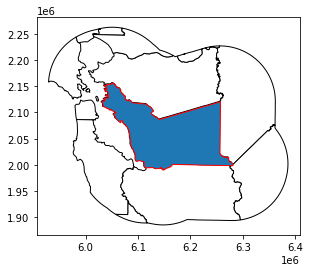

In [303]:
fig, ax = plt.subplots()
counties.plot(ax=ax, color='white', edgecolor='black')
alam.plot(ax=ax, edgecolor='red')



In [304]:
# DO NOT USE
# Intersection 
# Intersect overlay function clips geometry. This will not work because these are census tract.
# What we want is a filtered selection of any census tract that intersects with the buffered county
# geopandas.sjoin(left_df, right_df, how='inner', op='intersects', lsuffix='left', rsuffix='right')

#ctracts = gpd.overlay(counties, census_tracts, how='intersection')

In [201]:
replica

,origin_tract,destination_tract,week_starting,start_hour_local_time,start_hour_trips_count_avg_weekday
0,6085507807,06085507807,01-27-20,0,42
1,6085502906,aggregated_low_volumes,01-27-20,0,10
2,6075042602,06075012302,01-27-20,0,18
3,6001423602,06001423200,01-27-20,0,18
4,6001401000,06001400300,01-27-20,0,28
...,...,...,...,...,...
341520,6075010100,06081601700,01-27-20,23,15
341521,6085505305,06085505305,01-27-20,23,31
341522,6001450701,06001450604,01-27-20,23,17
341523,6085504317,aggregated_low_volumes,01-27-20,23,17
